# Step 2 – Time Series: ARIMA, SARIMA and the RF + ARIMA Hybrid
**Student:** Indrajith KTN 224078X

**AI use declaration:** This notebook's code was generated with the help of Claude (Anthropic)
and reviewed / run by the me.

**Idea:** ARIMA/SARIMA captures the trend and seasonality of monthly bird species richness.
A Random Forest then learns what ARIMA missed (the *residuals*).
Final forecast = ARIMA forecast + RF residual forecast.



In [1]:
import os, time, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

## 1. Build one monthly time series for Sri Lanka
Average species richness per month across all districts (132 months, 2014-2024, no gaps).
Temperature, rainfall and NDVI (monthly averages) are used as extra information.

In [2]:
DATA_PATH = "../data/processed/bird_monthly_data.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "bird_monthly_data.csv"
raw = pd.read_csv(DATA_PATH)
raw["date"] = pd.to_datetime(dict(year=raw["Year"], month=raw["Month"], day=1))

ts = raw.groupby("date").agg(richness=("species_richness", "mean"),
                             temp=("average_temperature", "mean"),
                             rain=("average_rainfall", "mean"),
                             ndvi=("average_ndvi", "mean")).asfreq("MS")
ts["richness"] = ts["richness"].interpolate()
print(ts.shape, ts.index.min().date(), "->", ts.index.max().date())
ts.head()

(132, 4) 2014-01-01 -> 2024-12-01


,richness,temp,rain,ndvi
date,,,,
2014-01-01,81.611111,24.040399,3.639957,0.700229
2014-02-01,79.904762,25.602695,0.910005,0.660944
2014-03-01,54.529412,26.436337,1.040043,0.599003
2014-04-01,27.666667,27.441152,6.240746,0.700200
2014-05-01,8.100000,26.634210,5.084917,0.511748


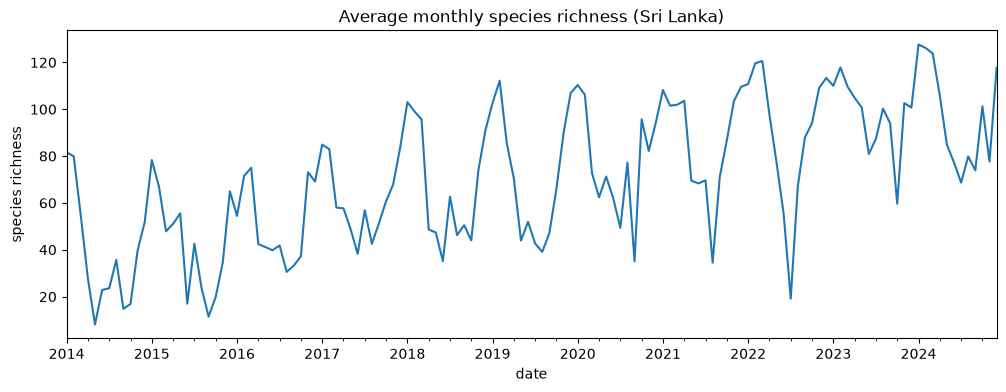

In [3]:
ts["richness"].plot(figsize=(12, 4), title="Average monthly species richness (Sri Lanka)")
plt.ylabel("species richness"); plt.show()

## 2. Time-based split (NO shuffling)
Train: 2014-2022. Test (hold-out): 2023-2024 = 24 months.

In [4]:
train = ts[ts.index < "2023-01-01"]
test  = ts[ts.index >= "2023-01-01"]
H = len(test)
y_train, y_test = train["richness"], test["richness"]
print("Train months:", len(train), " Test months:", H)

ts_results, ts_forecasts = [], {}

def score(name, pred, fit_time):
    ts_results.append({"Model": name,
                       "MAE":  mean_absolute_error(y_test, pred),
                       "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                       "MAPE": mean_absolute_percentage_error(y_test, pred) * 100,
                       "Train_Time_s": round(fit_time, 2)})
    ts_forecasts[name] = np.asarray(pred)
    print(f"{name:<28} MAE={ts_results[-1]['MAE']:.2f}  RMSE={ts_results[-1]['RMSE']:.2f}  MAPE={ts_results[-1]['MAPE']:.1f}%")

Train months: 108  Test months: 24


## 3. Baseline: seasonal naive (repeat the value of the same month last year)

In [5]:
start = time.time()
last_year = y_train.iloc[-12:].values
naive_pred = np.tile(last_year, int(np.ceil(H / 12)))[:H]
score("Seasonal Naive", naive_pred, time.time() - start)

Seasonal Naive               MAE=17.24  RMSE=23.59  MAPE=20.5%


## 4. ARIMA
Small grid search on (p, d, q) using AIC (lower = better).

In [6]:
best = None
for p, d, q in itertools.product([0, 1, 2, 3], [0, 1], [0, 1, 2]):
    try:
        m = ARIMA(y_train, order=(p, d, q)).fit()
        if best is None or m.aic < best[0]:
            best = (m.aic, (p, d, q))
    except Exception:
        pass
arima_order = best[1]
print("Best ARIMA order:", arima_order, " AIC =", round(best[0], 1))

start = time.time()
arima_fit = ARIMA(y_train, order=arima_order).fit()
arima_pred = arima_fit.forecast(steps=H).values
score("ARIMA", arima_pred, time.time() - start)

Best ARIMA order: (3, 1, 2)  AIC = 883.6
ARIMA                        MAE=17.07  RMSE=19.58  MAPE=18.0%


## 5. SARIMA (adds yearly seasonality, period = 12 months)

In [7]:
best_s = None
for p, d, q, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1], [0, 1]):
    try:
        m = SARIMAX(y_train, order=(p, d, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
        if best_s is None or m.aic < best_s[0]:
            best_s = (m.aic, (p, d, q), (P, 1, Q, 12))
    except Exception:
        pass
sarima_order, sarima_seasonal = best_s[1], best_s[2]
print("Best SARIMA:", sarima_order, sarima_seasonal, " AIC =", round(best_s[0], 1))

start = time.time()
sarima_fit = SARIMAX(y_train, order=sarima_order, seasonal_order=sarima_seasonal).fit(disp=False)
sarima_pred = sarima_fit.forecast(steps=H).values
score("SARIMA", sarima_pred, time.time() - start)

Best SARIMA: (0, 1, 1) (0, 1, 1, 12)  AIC = 790.5
SARIMA                       MAE=11.51  RMSE=15.94  MAPE=13.3%


## 6. Lag-feature XGBoost (for comparison)
Uses last month's values (lags 1, 2, 3, 12) + month. Forecasts step by step (recursive):
each new prediction becomes the next lag. No test data is used for the lags.

In [8]:
def month_feats(idx):
    m = idx.month
    return pd.DataFrame({"m_sin": np.sin(2 * np.pi * m / 12), "m_cos": np.cos(2 * np.pi * m / 12)}, index=idx)

LAGS = [1, 2, 3, 12]

def make_lag_table(series):
    df = month_feats(series.index)
    for l in LAGS:
        df[f"lag{l}"] = series.shift(l)
    return df

lag_train = make_lag_table(y_train).dropna()
Xl, yl = lag_train, y_train.loc[lag_train.index]

start = time.time()
xgb_ts = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3,
                      random_state=RANDOM_STATE, n_jobs=-1).fit(Xl, yl)

history = list(y_train.values)
xgb_pred = []
for date in test.index:
    row = {"m_sin": np.sin(2 * np.pi * date.month / 12), "m_cos": np.cos(2 * np.pi * date.month / 12)}
    for l in LAGS:
        row[f"lag{l}"] = history[-l]
    p = float(xgb_ts.predict(pd.DataFrame([row])[Xl.columns])[0])
    xgb_pred.append(p); history.append(p)
score("Lag-feature XGBoost", xgb_pred, time.time() - start)

Lag-feature XGBoost          MAE=18.70  RMSE=22.06  MAPE=20.7%


## 7. HYBRID: RF + ARIMA  (and RF + SARIMA)
1. Fit ARIMA on the training series.
2. Residuals = actual - ARIMA fitted values (what ARIMA could not explain).
3. Random Forest learns the residuals from: month, residual lags (1, 2, 3), and
   climate (temperature, rainfall, NDVI).
4. Final forecast = ARIMA forecast + RF residual forecast.

In [9]:
def hybrid_forecast(base_fit, base_forecast, name, rf_params=None):
    fitted = base_fit.fittedvalues
    resid = (y_train - fitted).dropna()
    # skip the first 13 months: ARIMA warm-up values are unreliable
    resid = resid.iloc[13:]

    def table(res_series, climate):
        df = month_feats(res_series.index)
        for l in [1, 2, 3]:
            df[f"res_lag{l}"] = res_series.shift(l)
        df[["temp", "rain", "ndvi"]] = climate.loc[res_series.index, ["temp", "rain", "ndvi"]]
        return df

    clim_all = ts[["temp", "rain", "ndvi"]]
    tab = table(resid, clim_all).dropna()
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_depth=6,
                               random_state=RANDOM_STATE, n_jobs=-1)
    start = time.time()
    rf.fit(tab, resid.loc[tab.index])
    fit_time = time.time() - start

    res_hist = list(resid.values)
    res_pred = []
    for date in test.index:
        row = {"m_sin": np.sin(2 * np.pi * date.month / 12), "m_cos": np.cos(2 * np.pi * date.month / 12),
               "res_lag1": res_hist[-1], "res_lag2": res_hist[-2], "res_lag3": res_hist[-3],
               "temp": clim_all.loc[date, "temp"], "rain": clim_all.loc[date, "rain"],
               "ndvi": clim_all.loc[date, "ndvi"]}
        r = float(rf.predict(pd.DataFrame([row])[tab.columns])[0])
        res_pred.append(r); res_hist.append(r)
    final = np.asarray(base_forecast) + np.asarray(res_pred)
    return final, rf, fit_time

start = time.time()
hyb_arima_pred, rf_res_arima, t1 = hybrid_forecast(arima_fit, arima_pred, "RF + ARIMA")
score("Hybrid RF + ARIMA", hyb_arima_pred, (time.time() - start))

start = time.time()
hyb_sarima_pred, rf_res_sarima, t2 = hybrid_forecast(sarima_fit, sarima_pred, "RF + SARIMA")
score("Hybrid RF + SARIMA", hyb_sarima_pred, (time.time() - start))

Hybrid RF + ARIMA            MAE=15.72  RMSE=18.60  MAPE=16.9%
Hybrid RF + SARIMA           MAE=13.05  RMSE=18.62  MAPE=15.3%


## 8. Comparison table and forecast plot

In [10]:
ts_df = pd.DataFrame(ts_results).sort_values("MAE").reset_index(drop=True)
ts_df.insert(0, "Rank", ts_df.index + 1)
best_ts = ts_df.loc[0, "Model"]
print("Best time-series model by MAE:", best_ts)
ts_df.round(3)

Best time-series model by MAE: SARIMA


,Rank,Model,MAE,RMSE,MAPE,Train_Time_s
0,1,SARIMA,11.512,15.945,13.343,0.14
1,2,Hybrid RF + SARIMA,13.053,18.624,15.283,1.62
2,3,Hybrid RF + ARIMA,15.716,18.597,16.895,1.63
3,4,ARIMA,17.065,19.581,18.028,0.17
4,5,Seasonal Naive,17.236,23.589,20.493,0.00
5,6,Lag-feature XGBoost,18.696,22.056,20.721,0.29


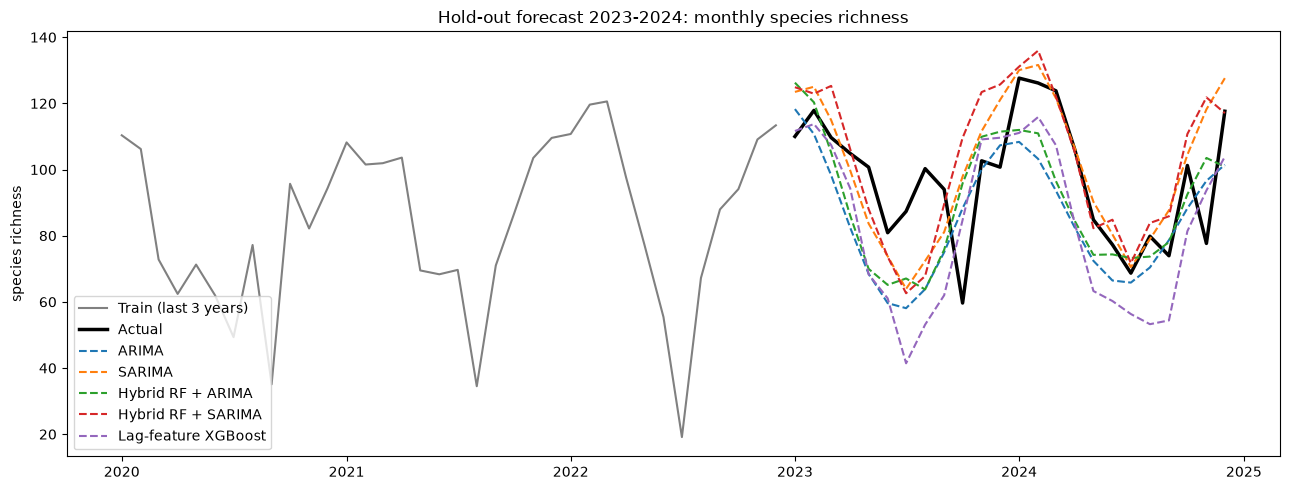

In [11]:
plt.figure(figsize=(13, 5))
plt.plot(y_train.index[-36:], y_train.values[-36:], label="Train (last 3 years)", color="gray")
plt.plot(test.index, y_test.values, label="Actual", color="black", linewidth=2.5)
for name in ["ARIMA", "SARIMA", "Hybrid RF + ARIMA", "Hybrid RF + SARIMA", "Lag-feature XGBoost"]:
    plt.plot(test.index, ts_forecasts[name], label=name, linestyle="--")
plt.title("Hold-out forecast 2023-2024: monthly species richness")
plt.ylabel("species richness"); plt.legend(); plt.tight_layout(); plt.show()

## 9. Did the RF residual step help?
Positive "improvement" = hybrid is better than its ARIMA/SARIMA base model.

In [12]:
mae = ts_df.set_index("Model")["MAE"]
print(f"ARIMA  MAE {mae['ARIMA']:.2f}  ->  RF+ARIMA  MAE {mae['Hybrid RF + ARIMA']:.2f}   "
      f"improvement: {mae['ARIMA'] - mae['Hybrid RF + ARIMA']:+.2f}")
print(f"SARIMA MAE {mae['SARIMA']:.2f}  ->  RF+SARIMA MAE {mae['Hybrid RF + SARIMA']:.2f}   "
      f"improvement: {mae['SARIMA'] - mae['Hybrid RF + SARIMA']:+.2f}")

ARIMA  MAE 17.07  ->  RF+ARIMA  MAE 15.72   improvement: +1.35
SARIMA MAE 11.51  ->  RF+SARIMA MAE 13.05   improvement: -1.54


## 10. Save results (used later by the dashboard)

In [13]:
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

ts_df.to_csv("../data/processed/timeseries_results.csv", index=False)
fc = pd.DataFrame({"date": test.index, "Actual": y_test.values})
for n, p in ts_forecasts.items():
    fc[n] = p
fc.to_csv("../data/processed/timeseries_forecasts.csv", index=False)

joblib.dump(arima_fit,  "../models/ts_arima.pkl")
joblib.dump(sarima_fit, "../models/ts_sarima.pkl")
joblib.dump(rf_res_arima,  "../models/ts_rf_residual_arima.pkl")
joblib.dump(rf_res_sarima, "../models/ts_rf_residual_sarima.pkl")
print("Saved: timeseries_results.csv, timeseries_forecasts.csv, time-series models")

Saved: timeseries_results.csv, timeseries_forecasts.csv, time-series models
